# Comerciantes e categorias no SynCCFD

Este notebook mostra os comerciantes do motor v2 (Fase 4 do plano `docs/plan-v0.2.md`).
Com `MerchantConfig`, o valor e o horário de uma compra passam a depender da
**categoria** do comerciante, e não só do cliente:

- os terminais pertencem a comerciantes físicos (de 1 a poucos terminais, na mesma
  cidade); os comerciantes online (CNP) têm um terminal virtual na sede;
- cada cliente tem uma preferência por categoria, $\mathrm{Dirichlet}(\alpha \cdot
  \text{pesos})$, e um fator de gasto, $\mathrm{LogNormal}(0; 0{,}5)$;
- uma compra sorteia a categoria pela preferência (com o fator de fim de semana), o
  tipo (CP, CNP), o comerciante (um favorito com probabilidade 0,6), a hora (perfil da
  categoria; CP só no horário de funcionamento) e o valor,
  $\text{mediana}_{\text{categoria}} \times \text{fator}_{\text{cliente}} \times
  \mathrm{LogNormal}(0, \sigma_{\text{categoria}})$.

As figuras são gravadas em PDF em `docs/figures/fase4/`.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from synccfd import DatasetGenerator
from synccfd.simulator.config import DEFAULT_CATEGORIES, FraudConfig, MerchantConfig

# Where the figures are saved (the tests point this to a temporary folder)
FIG_DIR = Path(os.environ.get("SYNCCFD_FIG_DIR", "../docs/figures/fase4"))
FIG_DIR.mkdir(parents=True, exist_ok=True)

CATEGORIES = {c.name: c for c in DEFAULT_CATEGORIES}
LABELS = {
    "supermercado": "supermercado", "restaurante_bar": "restaurante e bar",
    "posto_combustivel": "posto de combustível", "farmacia": "farmácia",
    "vestuario": "vestuário", "eletronicos": "eletrônicos", "viagem_turismo": "viagem e turismo",
    "ecommerce_marketplace": "e-commerce e marketplace", "servicos_digitais": "serviços digitais",
    "transporte_app": "transporte por app",
}
CHANNEL_LABELS = {"CP": "só CP", "CNP": "só CNP", "CP+CNP": "CP e CNP"}
# One color per channel (validated palette, fixed order); ink for text
CHANNEL_COLORS = {"CP": "#2a78d6", "CP+CNP": "#1baf7a", "CNP": "#eb6834"}
MUTED, INK, SECONDARY = "#8a8985", "#0b0b0b", "#52514e"

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6,
    "axes.edgecolor": "#b5b4ae", "axes.labelcolor": INK, "font.size": 10,
})

## As categorias

Os valores padrão (`DEFAULT_CATEGORIES`), escolhidos como no artigo: razoáveis, mas não
calibrados em dados reais.

In [2]:
pd.DataFrame([
    {"categoria": c.name, "canal": c.channel, "mediana (R$)": c.median_amount, "σ log": c.log_sigma,
     "peso": c.weight, "horário CP": f"{c.opening_hours[0]}–{c.opening_hours[1]} h" if c.has_cp else "—",
     "fim de semana": c.weekend_factor, "risco de skimming": c.skimming_risk if c.has_cp else None}
    for c in DEFAULT_CATEGORIES
]).set_index("categoria")

,canal,mediana (R$),σ log,peso,horário CP,fim de semana,risco de skimming
categoria,,,,,,,
supermercado,CP+CNP,120,0.7,0.20,8–21 h,1.2,1.0
restaurante_bar,CP,60,0.6,0.15,11–24 h,1.4,2.0
posto_combustivel,CP,150,0.4,0.10,6–23 h,1.0,3.0
farmacia,CP+CNP,70,0.6,0.08,8–22 h,1.0,1.0
vestuario,CP+CNP,180,0.7,0.08,10–22 h,1.3,1.0
eletronicos,CP+CNP,900,0.8,0.04,10–22 h,1.1,1.0
viagem_turismo,CNP,1200,0.7,0.03,—,1.0,NaN
ecommerce_marketplace,CNP,150,0.9,0.15,—,1.1,NaN
servicos_digitais,CNP,35,0.5,0.10,—,1.0,NaN


## Geração

Sem fraude e sem *drift*, para mostrar só o efeito dos comerciantes.

In [3]:
N_CUSTOMERS, N_TERMINALS, NB_DAYS = 5000, 10000, 90
START_DATE, SEED = "2023-01-01", 42

generator = DatasetGenerator(
    n_customers=N_CUSTOMERS, n_terminals=N_TERMINALS, nb_days=NB_DAYS, start_date=START_DATE,
    random_state=SEED, merchants=MerchantConfig(), fraud=FraudConfig(scenarios=()),
)
customers, terminals, transactions = generator.generate()
merchants = generator.merchant_profiles
print(f"{len(transactions):,} transações, {len(merchants):,} comerciantes "
      f"({(merchants.channel == 'CP').sum():,} físicos, {(merchants.channel == 'CNP').sum()} online)")
merchants.groupby(["MERCHANT_CATEGORY", "channel"]).agg(
    comerciantes=("MERCHANT_ID", "size"), terminais=("n_terminals", "sum")
).unstack(fill_value=0)

888,961 transações, 7,274 comerciantes (7,114 físicos, 160 online)


comerciantes       terminais      
channel                        CNP    CP       CNP    CP
MERCHANT_CATEGORY                                       
ecommerce_marketplace           20     0        20     0
eletronicos                     20   462        20   672
farmacia                        20   868        20  1196
posto_combustivel                0  1094         0  1530
restaurante_bar                  0  1627         0  2305
servicos_digitais               20     0        20     0
supermercado                    20  2190        20  3076
transporte_app                  20     0        20     0
vestuario                       20   873        20  1221
viagem_turismo                  20     0        20     0

## Valor por categoria

Distribuição dos valores de cada categoria (escala log). O losango marca a mediana
configurada; a cor indica o canal da categoria.

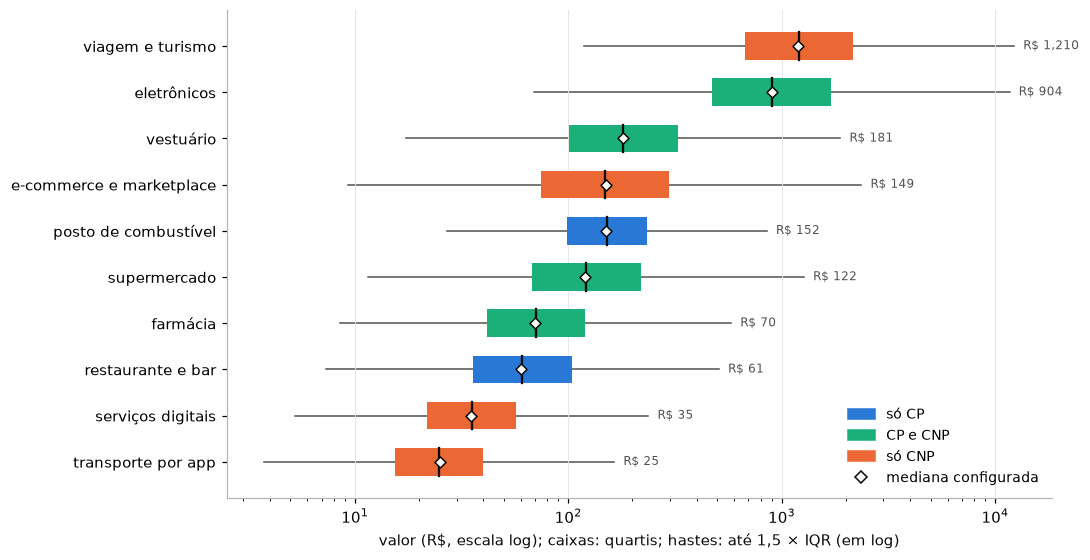

,mediana observada,configurada,diferenca_pct
MERCHANT_CATEGORY,,,
ecommerce_marketplace,148.66,150,-0.9
eletronicos,904.10,900,0.5
farmacia,70.37,70,0.5
posto_combustivel,151.76,150,1.2
restaurante_bar,61.09,60,1.8
servicos_digitais,35.27,35,0.8
supermercado,121.61,120,1.3
transporte_app,24.82,25,-0.7
vestuario,181.03,180,0.6


In [4]:
order = sorted(CATEGORIES, key=lambda name: CATEGORIES[name].median_amount)
fig, ax = plt.subplots(figsize=(10, 5.2))
for i, name in enumerate(order):
    category = CATEGORIES[name]
    values = transactions.loc[transactions.MERCHANT_CATEGORY == name, "TX_AMOUNT"]
    logs = np.log10(values[values > 0])
    q1, median, q3 = np.quantile(logs, [0.25, 0.5, 0.75])
    low = logs[logs >= q1 - 1.5 * (q3 - q1)].min()
    high = logs[logs <= q3 + 1.5 * (q3 - q1)].max()
    color = CHANNEL_COLORS[category.channel]
    ax.plot([10**low, 10**high], [i, i], color=SECONDARY, lw=1, zorder=1)
    ax.barh(i, 10**q3 - 10**q1, left=10**q1, height=0.6, color=color, zorder=2)
    ax.plot([10**median] * 2, [i - 0.3, i + 0.3], color=INK, lw=1.5, zorder=3)
    ax.scatter(category.median_amount, i, marker="D", s=26, color="#fcfcfb", edgecolor=INK,
               lw=1, zorder=4)
    ax.annotate(f"R$ {10**median:,.0f}", (10**high, i), xytext=(6, 0), textcoords="offset points",
                va="center", fontsize=8, color=SECONDARY)
ax.set_yticks(range(len(order)), [LABELS[n] for n in order])
ax.set_xscale("log")
ax.set_xlabel("valor (R$, escala log); caixas: quartis; hastes: até 1,5 × IQR (em log)")
ax.grid(axis="y", visible=False)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in CHANNEL_COLORS.values()]
handles.append(plt.Line2D([], [], marker="D", ls="", color="#fcfcfb", markeredgecolor=INK))
ax.legend(handles, [CHANNEL_LABELS[c] for c in CHANNEL_COLORS] + ["mediana configurada"],
          loc="lower right", frameon=False, fontsize=9)
fig.tight_layout()
fig.savefig(FIG_DIR / "comerciantes_valor_por_categoria.pdf", bbox_inches="tight")
plt.show()

transactions.groupby("MERCHANT_CATEGORY").TX_AMOUNT.median().rename("mediana observada").to_frame().assign(
    configurada=lambda d: [CATEGORIES[n].median_amount for n in d.index],
    diferenca_pct=lambda d: (100 * (d["mediana observada"] / d.configurada - 1)).round(1),
)

## Hora × categoria

Para cada categoria, a fração das suas compras em cada hora do dia. As compras CP só
acontecem no horário de funcionamento (marcado pelas bordas); as CNP seguem o perfil
da categoria o dia todo.

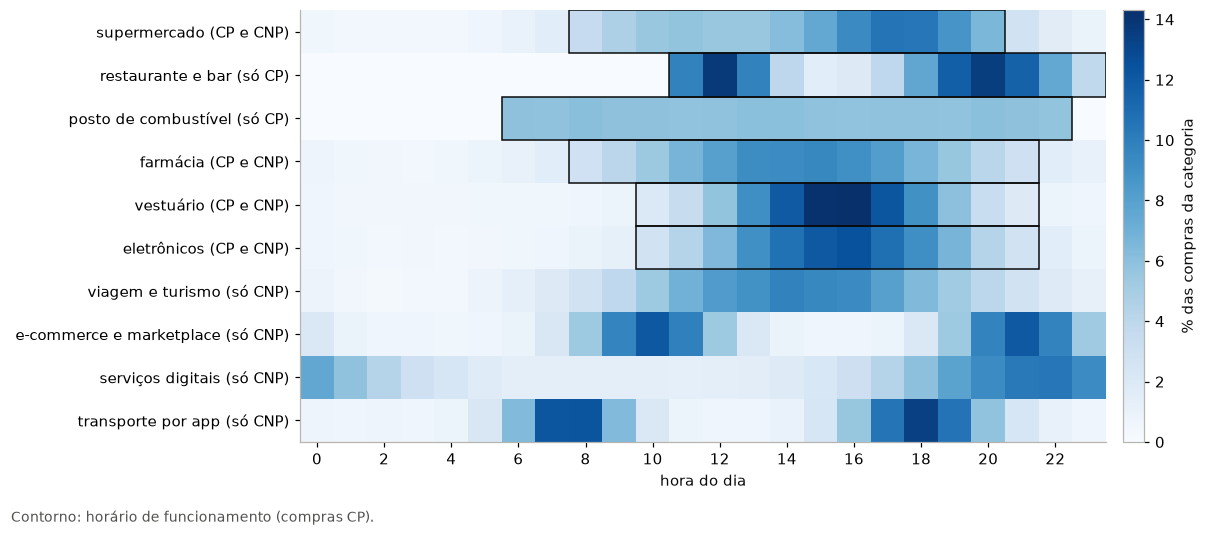

In [5]:
hour = (transactions.TX_TIME_SECONDS % 86400) // 3600
table = pd.crosstab(transactions.MERCHANT_CATEGORY, hour, normalize="index").reindex(
    index=list(CATEGORIES), columns=range(24), fill_value=0
)
fig, ax = plt.subplots(figsize=(11, 4.8))
image = ax.imshow(100 * table.to_numpy(), aspect="auto", cmap="Blues", vmin=0)
for i, name in enumerate(table.index):
    category = CATEGORIES[name]
    if category.has_cp:
        start, stop = category.opening_hours
        ax.add_patch(plt.Rectangle((start - 0.5, i - 0.5), stop - start, 1, fill=False,
                                   edgecolor=INK, lw=1))
ax.set_yticks(range(len(table)), [f"{LABELS[n]} ({CHANNEL_LABELS[CATEGORIES[n].channel]})"
                                  for n in table.index])
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("hora do dia")
ax.grid(False)
colorbar = fig.colorbar(image, ax=ax, fraction=0.03, pad=0.02)
colorbar.set_label("% das compras da categoria")
fig.text(0.01, 0.0, "Contorno: horário de funcionamento (compras CP).", fontsize=9, color=SECONDARY)
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(FIG_DIR / "comerciantes_hora_categoria.pdf", bbox_inches="tight")
plt.show()

## Participação das categorias

Fração das compras em cada categoria, dividida em CP e CNP, comparada ao peso
configurado (traço). As categorias só CP ficam abaixo do peso: um cliente sem
comerciante dessa categoria ao alcance (10 km) não compra nela, e a preferência dele é
redistribuída entre as outras categorias.

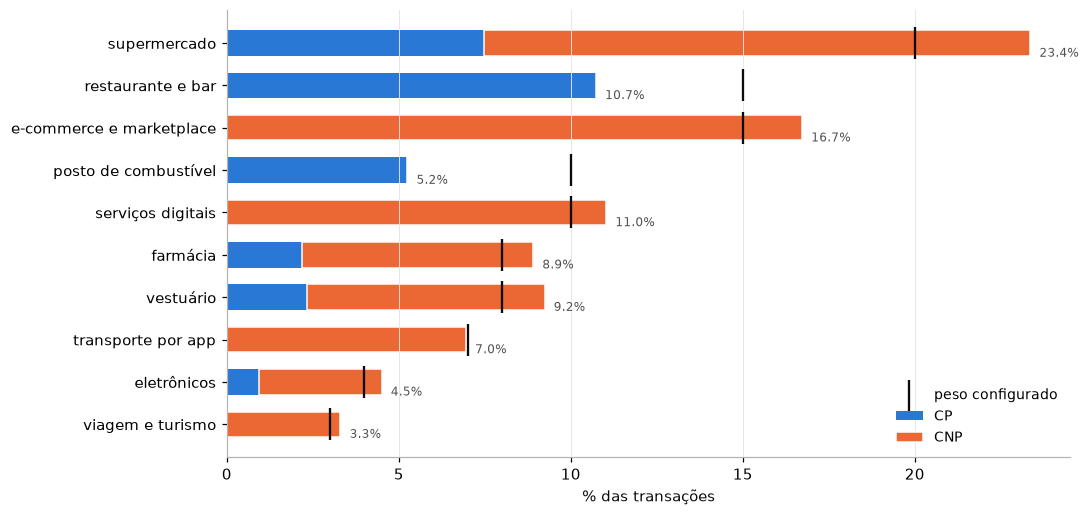

clientes sem terminal ao alcance: 13.9%; terminais ao alcance, mediana: 8


In [6]:
share = pd.crosstab(transactions.MERCHANT_CATEGORY, transactions.TX_TYPE, normalize="all")
share = share.reindex(index=sorted(CATEGORIES, key=lambda n: -CATEGORIES[n].weight), fill_value=0)
fig, ax = plt.subplots(figsize=(10, 4.8))
y = np.arange(len(share))[::-1]
ax.barh(y, 100 * share["CP"], color=CHANNEL_COLORS["CP"], height=0.6, label="CP")
ax.barh(y, 100 * share["CNP"], left=100 * share["CP"], color=CHANNEL_COLORS["CNP"], height=0.6,
        label="CNP", edgecolor="#fcfcfb", lw=1)
weights = np.array([CATEGORIES[n].weight for n in share.index])
ax.scatter(100 * weights, y, marker="|", s=420, color=INK, lw=1.5, label="peso configurado", zorder=3)
for yi, total in zip(y, 100 * share.sum(axis=1)):
    ax.annotate(f"{total:.1f}%", (total, yi), xytext=(6, -9), textcoords="offset points",
                fontsize=8, color=SECONDARY)
ax.set_yticks(y, [LABELS[n] for n in share.index])
ax.set_xlabel("% das transações")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right", frameon=False, fontsize=9)
fig.tight_layout()
fig.savefig(FIG_DIR / "comerciantes_participacao.pdf", bbox_inches="tight")
plt.show()

reach = customers.available_terminals.apply(len)
print(f"clientes sem terminal ao alcance: {(reach == 0).mean():.1%}; "
      f"terminais ao alcance, mediana: {reach.median():.0f}")

## Fidelidade

Com `loyalty=0.6`, cada cliente volta aos seus comerciantes favoritos de cada
categoria. Fração das compras de cada cliente, numa categoria, feitas nos dois
comerciantes em que ele mais compra.

In [7]:
counts = transactions.groupby(["CUSTOMER_ID", "MERCHANT_CATEGORY", "MERCHANT_ID"]).size()
groups = counts.groupby(level=[0, 1])
top2 = (groups.apply(lambda s: s.nlargest(2).sum()) / groups.sum())[groups.sum() >= 10]
top2.groupby(level=1).mean().rename(lambda n: LABELS[n]).round(2).to_frame("fração nos 2 favoritos")

,fração nos 2 favoritos
MERCHANT_CATEGORY,
e-commerce e marketplace,0.70
eletrônicos,0.68
farmácia,0.66
posto de combustível,0.82
restaurante e bar,0.81
serviços digitais,0.70
supermercado,0.64
transporte por app,0.70
vestuário,0.67
